# Active subspaces of force-field sensitivity in molecular dynamics of an epoxy resin

Stored data from

W. Edeling, M. Vassaux, Y. Yang, S. Wan, S. Guillas and P. V. Coveney, *Global ranking of the sensitivity of
interaction potential contributions within classical molecular dynamics force fields*, npj Computational
Materials 10:87, 2024. [doi:10.1038/s41524-024-01272-z](https://doi.org/10.1038/s41524-024-01272-z)

Wouter Edeling (1), Maxime Vassaux (2), Yiming Yang (3), Shunzhou Wan (4), Serge Guillas (3), Peter V. Coveney (4, 5, 6)

1 Scientific Computing Group, Centrum Wiskunde & Informatica, Amsterdam, The Netherlands; 2 Université de
Rennes, CNRS, Institut de Physique de Rennes, UMR 6251, Rennes, France; 3 Department of Statistical Science,
University College London, London, United Kingdom; 4 Centre for Computational Science, University College
London, London, United Kingdom; 5 Advanced Research Computing Centre, University College London, London,
United Kingdom; 6 Informatics Institute, University of Amsterdam, Amsterdam, The Netherlands.

Notebook: Claude (Anthropic) for P. Constantine, 2026

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

import active_subspaces as ac
from active_subspaces.subspaces import OPG

SEED = 195
T0 = time.time()
# OLS (the cross-check) warns that its assumptions hold exactly only for elliptical inputs; the
# notebook states this caveat in the text.
warnings.filterwarnings('ignore', category=ac.ValidityWarning)

## Summary

Edeling et al. ran LAMMPS molecular dynamics of a cross-linked epoxy resin at 500 Monte Carlo points of 103
force-field parameters (each uniform within ±15 % of its default), with 20 replica runs per point, and
published the elastic outputs; this notebook analyses the replica means of their stiffness output $E_{11}$
(the file the paper uses as its "Young's modulus $E$"; the stored outputs identify it as the stiffness
component $C_{11}$)
and of the Poisson ratio. Without gradients and with $M = 500$ runs in $m = 103$ dimensions, it estimates the
subspace with the outer product of local linear gradients (OPG) and finds one dominant eigenvalue followed by
a flat tail ($\lambda_2/\lambda_3$ between 1.04 and 1.27); the size of the gap depends on the estimator's neighbourhood size $p$
($\lambda_1/\lambda_2$ from 42.9 to 739.1 for $E_{11}$ and from 81.5 to 2144.8 for the Poisson ratio over
$p$ = 130 to 400), so the notebook calibrates the trailing eigenvalues against three nulls (replica noise
alone, an exact one-dimensional ridge, and that ridge with shuffled residuals). A cubic in the one
active variable predicts both outputs with leave-one-out $R^2$ 0.9615 and 0.9606, no second direction is
detectable, and the leading inputs agree with the paper's Fig. 5 (10 and 9 of the top 10); the published DAS
$\lambda_2/\lambda_1$ (Fig. 2a) is comparable to OPG's at the smallest $p$ and larger than OPG's at the default
$p$ and above, the KAS-GP $\lambda_2/\lambda_1$ is larger at every $p$, and all of these ratios depend on the
estimator.

## Active subspaces in brief

For a function $f(\mathbf{x})$ of $m$ inputs with density $\rho$, the active subspace is spanned by the
leading eigenvectors of $\mathbf{C} = \int \nabla f\, \nabla f^\top \rho\, d\mathbf{x}
= \mathbf{W}\boldsymbol{\Lambda}\mathbf{W}^\top$ (the paper's Eqs. 1–2, p. 10); a large gap after the $n$-th
eigenvalue means that $f$ varies mostly along the $n$ active variables $\mathbf{y} = \mathbf{W}_1^\top
\mathbf{x}$, which a sufficient summary plot of $f$ against $\mathbf{y}$ shows. The diagonal of $\mathbf{C}$
holds the global derivative-based sensitivity indices $\nu_i = \int (\partial f/\partial x_i)^2 \rho\,
d\mathbf{x}$ (the paper's Eqs. 5–6, p. 10). Without gradients, $\mathbf{C}$ is estimated from values, here by
fitting a linear function on the nearest neighbours of each sample and averaging the outer products of the
fitted gradients (OPG). See P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in
Parameter Studies*, SIAM, 2015, [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

## The model

**System and simulation** (paper, Methods, pp. 9–10). Tetraglycidyl methylene dianiline (TGMDA) cured with
polyetheramine (PEA) in a 1:1 ratio, packed and cross-linked with an in-house code; "an ensemble of 20
replicas for which 91.8% ± 0.5% of the functional groups have reacted". The runs used LAMMPS on SuperMUC-NG
"following the ELASTIC procedure from the LAMMPS examples database". The authors' input script
(`molecular_models/epoxy_elasticity/simulation.in` of their repository, not shipped here) sets LAMMPS
`units real`, `pair_style lj/cut/coul/long 12.0 9.0`, harmonic bonds and angles, OPLS dihedrals, PPPM
electrostatics, SHAKE with a 2 fs time step and an NVT stage at 300 K. Replicas are runs "at the same
epistemic parameters and a different random seed" (p. 2); the paper calls the seed the source of aleatoric
uncertainty.

**Force field.** The 103 inputs are coefficients of the bonded and Lennard-Jones terms; partial charges are
not varied (p. 3). The functional forms of the LAMMPS styles named in the input script (LAMMPS documentation,
not printed in the paper) are

$$U = \sum_{\text{bonds}} K_b (r - r_0)^2 + \sum_{\text{angles}} K_\theta (\theta - \theta_0)^2
+ \sum_{\text{dihedrals}} \tfrac12\left[K_1(1+\cos\phi) + K_2(1-\cos 2\phi) + K_3(1+\cos 3\phi) + K_4(1-\cos 4\phi)\right]
+ \sum_{\text{pairs}} 4\varepsilon\left[(\sigma/r)^{12} - (\sigma/r)^6\right] + U_{\text{Coulomb}}.$$

**Inputs** ($m = 103$; Table 1, p. 3). Every input is independent and uniform,
$x_i \sim \mathcal{U}(0.85\,\bar x_i, 1.15\,\bar x_i)$ about its default $\bar x_i$ (p. 3; the
setTemperature exception there concerns the binding-energy studies, not this one). The names and defaults
are the authors' (`epoxy.params.json`; Supplementary Table 1 of the paper, not read here). The role of each
name (first letter = term, last digit = coefficient) and the units are inferred from the LAMMPS styles: each
class of defaults equals one coefficient row of the authors' LAMMPS data file (`check_accuracy.py`). For the 14 dihedral coefficients with a
negative default the interval runs from $1.15\,\bar x_i$ to $0.85\,\bar x_i$.

| names | count | coefficient | units | defaults | source |
|---|---|---|---|---|---|
| p11 … p91 | 9 | LJ well depth $\varepsilon$ of 9 atom classes | kcal/mol | 0.01–0.17 | Table 1, p. 3; `epoxy_defaults.csv` |
| p12 … p92 | 9 | LJ diameter $\sigma$ | Å | 2.42–3.55 | same |
| b11 … b101 | 10 | bond stiffness $K_b$ of 10 bond classes | kcal/mol/Å² | 268–553 | same |
| b12 … b102 | 10 | bond length $r_0$ | Å | 0.945–1.529 | same |
| a11 … a151 | 15 | angle stiffness $K_\theta$ of 15 angle classes | kcal/mol/rad² | 33–70 | same |
| a12 … a152 | 15 | equilibrium angle $\theta_0$ | deg | 106.4–120 | same |
| d11 … d181 | 35 | nonzero OPLS coefficients $K_1$–$K_4$ of 17 dihedral classes | kcal/mol | −7.582 to 8 | same |

The 37 OPLS coefficients whose default is zero (among them all four of class d7) are not varied: a ±15 %
range about zero is empty.

**Quantities of interest.** The authors' notebook uses the file `E11` and states that it is "the 11
component of the elasticity tensor (equal to the Young's modulus E in this isotropic case)"; the paper calls
it the Young's modulus $E$ (pp. 3–6, Fig. 3, Table 2) and also analyses the Poisson ratio. Each QoI is
ensemble-averaged over the 20 replicas unless noted (p. 10). The stored outputs (next sections) show that
$E_{11}$ is the stiffness component $C_{11}$, not the isotropic Young's modulus; this notebook therefore
calls it $E_{11}$. Units: Pa (Fig. 3) and dimensionless.

**Gradients.** None: MD gives no derivatives with respect to the force-field coefficients, and finite
differences would need 104 runs of 20 replicas per gradient. The paper also works without gradients (DAS
and KAS-GP, pp. 4, 10).

**Sampling design.** Simple Monte Carlo: 500 independent draws from the product of uniforms, generated with
EasyVVUQ (pp. 3, 10), each run as 20 replicas (Table 1).

## Load the data

The inputs (500 × 103, physical units), the defaults, and the 500 × 20 replica outputs of $E_{11}$ and the
Poisson ratio, converted losslessly from the authors' repository by `convert_data.py`. Row $i$ of every
output file belongs to row $i$ of the inputs.

In [2]:
def load(name):
    """Values and column names (without units) of one of this data set's CSV files."""
    with open(name) as fh:
        fh.readline()
        cols = [c.split(' [')[0] for c in fh.readline()[2:].strip().split(',')]
    return np.loadtxt(name, delimiter=',', ndmin=2), cols


X, names = load('epoxy_inputs.csv')            # (500, 103) force-field parameters, physical units
x0 = load('epoxy_defaults.csv')[0].ravel()     # (103,) default values
E_rep = load('epoxy_E11_replicas.csv')[0]      # (500, 20) E11 [Pa] (the paper's E), one column per replica
nu_rep = load('epoxy_poisson_replicas.csv')[0] # (500, 20) Poisson ratio [1]
M, m = X.shape
R = E_rep.shape[1]
print('X', X.shape, ' defaults', x0.shape, ' E replicas', E_rep.shape, ' Poisson replicas', nu_rep.shape)
ratio = X / x0
print(f'x / x_default: min {ratio.min():.6f}, max {ratio.max():.6f}; negative defaults: {int((x0 < 0).sum())}')

X (500, 103)  defaults (103,)  E replicas (500, 20)  Poisson replicas (500, 20)
x / x_default: min 0.850001, max 1.149988; negative defaults: 14


All inputs lie within ±15 % of their defaults (ratios 0.850001 to 1.149988). The next cell recomputes the
first four moments of Table 2 (p. 6) from all 10,000 output samples.

In [3]:
# Table 2 of the paper: moments of all 500 x 20 = 10,000 output samples (np.std with ddof=0,
# scipy skew and excess kurtosis, as in the authors' notebook)
for label, Y in [('E11 [Pa]', E_rep), ('Poisson ratio', nu_rep)]:
    y = Y.ravel()
    print(f'{label:14s} N = {y.size}: mean {y.mean():.4g}, std {y.std():.4g}, '
          f'skew {stats.skew(y):.3f}, excess kurtosis {stats.kurtosis(y):.3f}')
print('single-replica Poisson values below 0:', int((nu_rep < 0).sum()),
      ' rows with such a value:', int((nu_rep < 0).any(axis=1).sum()))

E11 [Pa]       N = 10000: mean 6.541e+09, std 3.222e+09, skew 1.605, excess kurtosis 3.756
Poisson ratio  N = 10000: mean 0.34, std 0.05274, skew -1.012, excess kurtosis 0.970
single-replica Poisson values below 0: 1  rows with such a value: 1


The moments agree with Table 2 to its printed precision ($E$: 6.54e9, 3.22e9, 1.61, 3.76; Poisson: 0.34,
0.053, −1.01, 0.97), so these files are the paper's data. One single-replica Poisson value is negative (in
one row); it is kept, as is every row: the notebook drops no data.

### What the $E_{11}$ file holds

The LAMMPS ELASTIC example averages the stiffness components to cubic symmetry and reports bulk modulus
$K = (\bar C_{11} + 2\bar C_{12})/3$, shear modulus $G = (\bar C_{11} - \bar C_{12})/2$ ("shear2") and
Poisson ratio $\bar C_{12}/(\bar C_{11} + \bar C_{12})$. If $E_{11}$ were $C_{11}$, then
$K + 4G/3$ would equal the mean of $E_{11}, E_{22}, E_{33}$.

In [4]:
# What the E11 file holds: relations among the six stored outputs (ELASTIC averaging of the C_ij)
E22_rep = load('epoxy_E22_replicas.csv')[0]
E33_rep = load('epoxy_E33_replicas.csv')[0]
K_rep = load('epoxy_bulk_replicas.csv')[0]
G_rep = load('epoxy_shear2_replicas.csv')[0]
c11 = (E_rep + E22_rep + E33_rep) / 3
dev_c = np.max(np.abs(K_rep + 4 * G_rep / 3 - c11) / c11)
dev_nu = np.max(np.abs((3 * K_rep - 2 * G_rep) / (2 * (3 * K_rep + G_rep)) - nu_rep))
young = 9 * K_rep * G_rep / (3 * K_rep + G_rep)
print(f'max |K + 4G/3 - mean(E11, E22, E33)| / mean: {dev_c:.1e}')
print(f'max |(3K - 2G) / (2(3K + G)) - Poisson|: {dev_nu:.1e}')
print(f'isotropic Young modulus 9KG/(3K + G) divided by E11: median {np.median(young / E_rep):.3f}, '
      f'range {np.min(young / E_rep):.3f} to {np.max(young / E_rep):.3f}')
an_run = (E_rep / E22_rep).ravel()
an_mean = E_rep.mean(axis=1) / E22_rep.mean(axis=1)
print(f'E11/E22 per run: median {np.median(an_run):.3f}, 1-99 % {np.percentile(an_run, 1):.3f} to '
      f'{np.percentile(an_run, 99):.3f}; of the 500 replica means: median {np.median(an_mean):.3f}, '
      f'1-99 % {np.percentile(an_mean, 1):.3f} to {np.percentile(an_mean, 99):.3f}')

max |K + 4G/3 - mean(E11, E22, E33)| / mean: 6.7e-15
max |(3K - 2G) / (2(3K + G)) - Poisson|: 1.9e-15
isotropic Young modulus 9KG/(3K + G) divided by E11: median 0.605, range 0.344 to 1.202
E11/E22 per run: median 1.032, 1-99 % 0.790 to 1.516; of the 500 replica means: median 1.031, 1-99 % 0.960 to 1.202


Both identities hold to rounding level (relative deviations of order 1e-15), so the `E11` output is the
stiffness component $C_{11}$ of each run and the Poisson ratio is the isotropic one built from the averaged
stiffnesses. The paper's text does not say how its "Young's modulus" was computed; the file the paper (and the
authors' notebook) uses as $E$ is $C_{11}$. The isotropic Young's modulus $9KG/(3K+G)$ is a median 0.605 of
$E_{11}$. Its range
across runs, 0.344 to 1.202, includes values above 1, which an isotropic $C_{11}$ cannot give: single runs are
anisotropic ($E_{11}/E_{22}$ from 0.790 to 1.516, 1st to 99th percentile). Averaging the 20 replicas does not
remove a systematic offset: the median $E_{11}/E_{22}$ of the 500 replica means is 1.031, so $E_{11}$ sits about
3 % above $E_{22}$ even after averaging. This suggests that the replicas share structures or that the strain
protocol is directional; either way the QoI depends on which direction is called 1. The analysis below uses
$E_{11}$ as stored, as the paper did.

### Replica noise

Each QoI is the mean of 20 replicas. Its noise variance is estimated row by row from the replica spread
(variance with ddof 1, divided by 20); the "noise share" is its average divided by the variance of the
replica means across the 500 input points.

In [5]:
def replica_noise(Y):
    """Replica mean, and the noise variance of that mean estimated from the replicas."""
    f = Y.mean(axis=1)
    noise_var = Y.var(axis=1, ddof=1) / Y.shape[1]   # variance of the mean of R replicas, per row
    return f, noise_var


E, E_noise = replica_noise(E_rep)
nu, nu_noise = replica_noise(nu_rep)
for label, f, nv, Y in [('E11', E, E_noise, E_rep), ('Poisson', nu, nu_noise, nu_rep)]:
    share = nv.mean() / f.var(ddof=1)
    print(f'{label:8s} var of replica means {f.var(ddof=1):.3e}; mean noise var of a mean {nv.mean():.3e}; '
          f'noise share {share:.2e} (R^2 ceiling {1 - share:.4f}); '
          f'single-replica noise share {Y.var(axis=1, ddof=1).mean() / Y[:, 0].var(ddof=1):.3f}')

E11      var of replica means 1.023e+19; mean noise var of a mean 8.871e+15; noise share 8.67e-04 (R^2 ceiling 0.9991); single-replica noise share 0.017
Poisson  var of replica means 2.469e-03; mean noise var of a mean 1.670e-05; noise share 6.76e-03 (R^2 ceiling 0.9932); single-replica noise share 0.111


The replica noise is a small part of the variation of the means: a share of 8.67e-04 for $E_{11}$ and
6.76e-03 for the Poisson ratio, so no function of the inputs can explain more than $R^2$ = 0.9991 and
0.9932 of the replica means. For one replica the shares are 0.017 and 0.111, which is why the paper averages
over replicas (p. 4, Fig. 4). This agrees with the paper's conclusion that the epistemic (force-field)
uncertainty dominates the aleatoric one (p. 4, Fig. 1).

## Estimate the subspace

The input space is the product of the 103 uniform intervals; the library maps each input linearly to
$[-1, 1]$, as the authors' notebooks do. For the 14 negative-default dihedral coefficients the authors'
scaling uses $0.85\,\bar x_i$ as the lower end, so their normalized coordinate is the negative of the one
here; eigenvalues and the indices $\nu_i$ do not change, and the signs of those 14 eigenvector components
are reversed relative to the authors'.

In [6]:
lower = np.minimum(0.85 * x0, 1.15 * x0)
upper = np.maximum(0.85 * x0, 1.15 * x0)
space = ac.Uniform(lower, upper, names=names)
print('coefficients of a full quadratic in m inputs, (m+1)(m+2)/2 =', (m + 1) * (m + 2) // 2)
print('m =', space.dim, ' inputs with a negative default (normalized axis reversed relative to the authors):',
      [n for n, v in zip(names, x0) if v < 0])

coefficients of a full quadratic in m inputs, (m+1)(m+2)/2 = 5460
m = 103  inputs with a negative default (normalized axis reversed relative to the authors): ['d11', 'd21', 'd22', 'd31', 'd41', 'd42', 'd51', 'd52', 'd61', 'd62', 'd142', 'd152', 'd162', 'd172']


**Estimator.** No gradients are available, and $M = 500$ runs in $m = 103$ dimensions. A global quadratic
has $(m+1)(m+2)/2$ = 5,460 coefficients, more than the number of runs, so QPHD cannot be fitted. A global
linear fit (OLS) gives a single direction and no eigenvalue spectrum, so it cannot be compared with the
published eigenvalues; it is used below as a cross-check of the direction. The notebook uses OPG: at each
of the 500 points a linear function is fitted to its $p = \lfloor 1.7m \rfloor = 175$ nearest neighbours,
and $\hat{\mathbf{C}} = \frac1M \sum_i \hat g_i \hat g_i^\top$. With 103 inputs these neighbourhoods hold 35 %
of the runs, so the fitted gradients are smoothed and the trailing eigenvalues depend on $p$; the nulls and
the $p$ sweep below measure how much. The bootstrap (200 replicates, seed `SEED`) resamples the 500 rows and
recomputes all local fits. The dimension is fixed at $n = 1$ here and justified below.

In [7]:
P = int(np.floor(1.7 * m))   # neighbours per local linear fit (the OPG default)
t = time.time()
subs = {}
for label, f in [('E11', E), ('Poisson', nu)]:
    s = ac.active_subspace(space=space, X=X, f=f, estimator=OPG(p=P), n=1, nboot=200,
                           bootstrap_vectors=1, rng=SEED, qoi=label)
    # sign rule: the QoI decreases along y1, as in the published Fig. 3
    subs[label] = ac.orient(s, by='covariance', X=X, f=-f)
print(f'p = {P} neighbours per fit ({P / M:.0%} of the runs); OPG with 200 bootstrap replicates for both QoIs: {time.time() - t:.0f} s')


def ratio_table(s, k=6):
    lam = s.eigenvalues
    rb = s.bootstrap_eigenvalues / s.bootstrap_eigenvalues[:, :1]
    lo, hi = np.percentile(rb[:, :k], [2.5, 97.5], axis=0)
    for j in range(k):
        print(f'  lambda_{j + 1}/lambda_1 = {lam[j] / lam[0]:.4f}  (bootstrap 95%: {lo[j]:.4f} to {hi[j]:.4f})')
    print(f'  lambda_1/lambda_2 = {lam[0] / lam[1]:.1f}, lambda_2/lambda_3 = {lam[1] / lam[2]:.2f}, '
          f'lambda_3/lambda_4 = {lam[2] / lam[3]:.2f}')


for label, s in subs.items():
    print(label)
    ratio_table(s)

p = 175 neighbours per fit (35% of the runs); OPG with 200 bootstrap replicates for both QoIs: 554 s
E11
  lambda_1/lambda_1 = 1.0000  (bootstrap 95%: 1.0000 to 1.0000)
  lambda_2/lambda_1 = 0.0101  (bootstrap 95%: 0.0079 to 0.0156)
  lambda_3/lambda_1 = 0.0092  (bootstrap 95%: 0.0062 to 0.0112)
  lambda_4/lambda_1 = 0.0064  (bootstrap 95%: 0.0055 to 0.0092)
  lambda_5/lambda_1 = 0.0056  (bootstrap 95%: 0.0049 to 0.0083)
  lambda_6/lambda_1 = 0.0050  (bootstrap 95%: 0.0043 to 0.0071)
  lambda_1/lambda_2 = 99.4, lambda_2/lambda_3 = 1.09, lambda_3/lambda_4 = 1.45
Poisson
  lambda_1/lambda_1 = 1.0000  (bootstrap 95%: 1.0000 to 1.0000)
  lambda_2/lambda_1 = 0.0046  (bootstrap 95%: 0.0044 to 0.0075)
  lambda_3/lambda_1 = 0.0043  (bootstrap 95%: 0.0038 to 0.0061)
  lambda_4/lambda_1 = 0.0038  (bootstrap 95%: 0.0034 to 0.0054)
  lambda_5/lambda_1 = 0.0035  (bootstrap 95%: 0.0030 to 0.0048)
  lambda_6/lambda_1 = 0.0032  (bootstrap 95%: 0.0028 to 0.0043)
  lambda_1/lambda_2 = 216.6, lambda_2/la

For $E_{11}$, $\lambda_2/\lambda_1$ = 0.0101 (bootstrap 95 % interval 0.0079 to 0.0156), and for the
Poisson ratio 0.0046 (0.0044 to 0.0075). After the first gap the spectrum is flat: $\lambda_2/\lambda_3$ =
1.09 for both QoIs and $\lambda_3/\lambda_4$ = 1.45 and 1.12, so no second gap follows. (Some bootstrap
intervals are strongly asymmetric, e.g. 0.0044 to 0.0075 about 0.0046 for the Poisson ratio; the bootstrap
of eigenvalues is a rough guide here.)

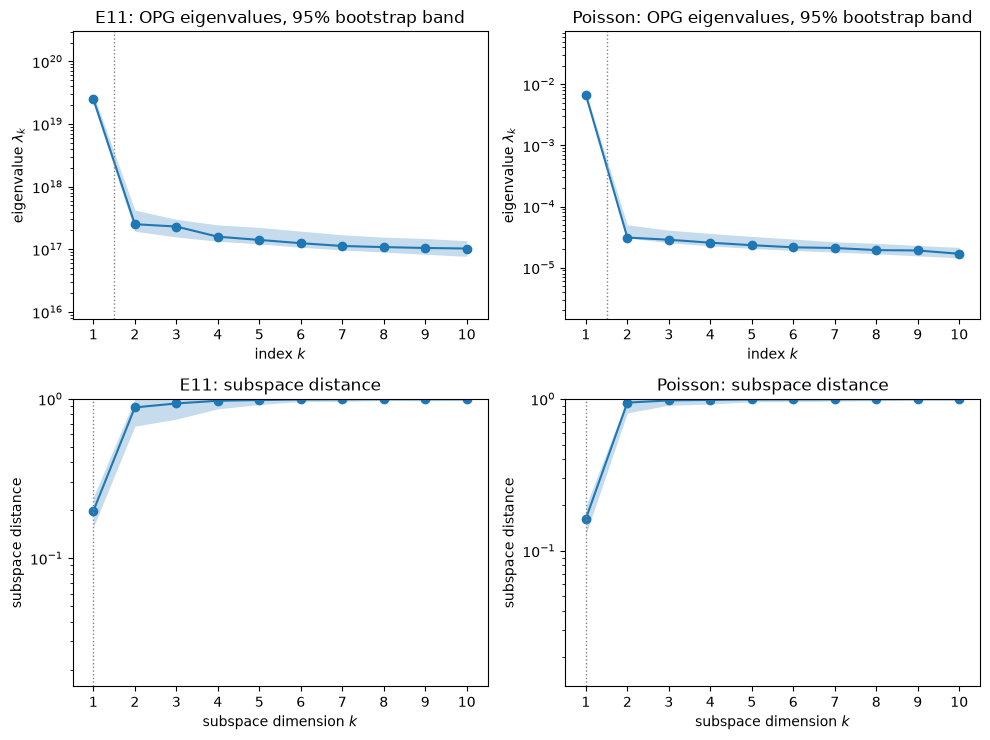

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7.5))
for col, (label, s) in enumerate(subs.items()):
    ac.plotting.plot_eigenvalues(s, k_max=10, ax=axes[0, col])
    axes[0, col].set_title(f'{label}: OPG eigenvalues, 95% bootstrap band')
    ac.plotting.plot_subspace_errors(s, k_max=10, ax=axes[1, col])
    axes[1, col].set_title(f'{label}: subspace distance')
fig.tight_layout()
plt.close(fig)
fig

The eigenvalue plots show one leading eigenvalue and then a slowly decaying tail; the subspace distance is
smallest at $k = 1$.

### Is the tail noise, estimator error or structure? Three nulls

The same estimator is applied to three synthetic responses at the same 500 inputs:

(a) **replica noise only**: the data mean plus a draw of the noise of a 20-replica mean, made by flipping the
signs of each replica's deviation from its row mean at random (this keeps the row-to-row size of the noise);

(b) **an exact one-dimensional ridge**: the cubic in $y_1$ fitted to the data, plus a noise draw as in (a);

(c) **the ridge with shuffled residuals**: the same cubic plus the data's own residuals from it, permuted
across rows, which keeps their size but removes any dependence on the inputs.

In [9]:
rng = np.random.default_rng(SEED)


def opg_eigs(f, p=P):
    return ac.active_subspace(space=space, X=X, f=f, estimator=OPG(p=p), n=1).eigenvalues


def sign_flip_noise(Y):
    """A draw of the replica noise of the mean: random signs on each replica's deviation from the row mean."""
    dev = Y - Y.mean(axis=1, keepdims=True)
    return (rng.choice([-1.0, 1.0], size=Y.shape) * dev).mean(axis=1)


def ridge_fit(s, f, degree=3):
    """Cubic in y1 fitted to f; returns the fitted values g(y1)."""
    sg = ac.fit_surrogate(X=X, f=f, subspace=s, kind='poly', degree=degree)
    return f - sg.residuals


null = {}
for label, f, Y in [('E11', E, E_rep), ('Poisson', nu, nu_rep)]:
    lam = subs[label].eigenvalues
    g = ridge_fit(subs[label], f)
    noise = np.array([opg_eigs(f.mean() + sign_flip_noise(Y))[:4] for _ in range(30)]) / lam[0]
    ridge = np.array([opg_eigs(g + sign_flip_noise(Y))[:4] for _ in range(20)])
    ridge = ridge / ridge[:, :1]
    shuf = np.array([opg_eigs(g + rng.permutation(f - g))[:4] for _ in range(20)])
    shuf = shuf / shuf[:, :1]
    null[label] = dict(noise=noise, ridge=ridge, shuf=shuf)
    print(f'{label}: data lambda_2..4 / lambda_1 = {np.round(lam[1:4] / lam[0], 4)}')
    print(f'   (a) replica noise only (30 draws): lambda_1,null / lambda_1 median {np.median(noise[:, 0]):.1e}, '
          f'max {noise[:, 0].max():.1e}')
    print(f'   (b) exact 1-D ridge + replica noise (20 draws): lambda_2..4/lambda_1 mean '
          f'{np.round(ridge[:, 1:].mean(0), 4)}, max {np.round(ridge[:, 1:].max(0), 4)}')
    print(f'   (c) 1-D ridge + shuffled residuals (20 draws): lambda_2..4/lambda_1 mean '
          f'{np.round(shuf[:, 1:].mean(0), 4)}, range {np.round(shuf[:, 1].min(), 4)} to {np.round(shuf[:, 1].max(), 4)} for k = 2')

E11: data lambda_2..4 / lambda_1 = [0.0101 0.0092 0.0064]
   (a) replica noise only (30 draws): lambda_1,null / lambda_1 median 3.5e-04, max 5.6e-04
   (b) exact 1-D ridge + replica noise (20 draws): lambda_2..4/lambda_1 mean [0.0074 0.0052 0.0035], max [0.0077 0.0054 0.0036]
   (c) 1-D ridge + shuffled residuals (20 draws): lambda_2..4/lambda_1 mean [0.0085 0.0064 0.0053], range 0.0067 to 0.0101 for k = 2


Poisson: data lambda_2..4 / lambda_1 = [0.0046 0.0043 0.0038]
   (a) replica noise only (30 draws): lambda_1,null / lambda_1 median 2.5e-03, max 3.1e-03
   (b) exact 1-D ridge + replica noise (20 draws): lambda_2..4/lambda_1 mean [0.0026 0.0019 0.0017], max [0.003  0.0021 0.0019]
   (c) 1-D ridge + shuffled residuals (20 draws): lambda_2..4/lambda_1 mean [0.0039 0.0034 0.0032], range 0.0032 to 0.0046 for k = 2


(a) Replica noise alone produces eigenvalues of only 3.5e-04 (median; max 5.6e-04) of the data's
$\lambda_1$ for $E_{11}$, far below the data's $\lambda_2/\lambda_1$ = 0.0101. For the Poisson ratio the
noise floor is higher, 2.5e-03 (max 3.1e-03), against 0.0046: its trailing eigenvalues are within a factor
of two of the replica noise.

(b) An exact ridge already gives $\lambda_2/\lambda_1$ = 0.0074 for $E_{11}$ and 0.0026 for the Poisson
ratio (means of 20 draws; max 0.0077 and 0.0030). Most of the tail is thus estimator error of the local
linear fits on a curved one-dimensional function, not a second direction; the data's values are larger, so
the data are not exactly a ridge.

(c) With the residuals shuffled, $\lambda_2/\lambda_1$ ranges over 0.0067 to 0.0101 ($E_{11}$) and 0.0032 to
0.0046 (Poisson), and the data's 0.0101 and 0.0046 sit at the top of these ranges. The variance that the cubic
does not explain is real (it is much larger than the replica noise), but its eigenvalue
signature is reproduced, to within the range of 20 draws, by residuals with no dependence on the inputs: the
data show no detectable concentration of that variation along a second direction.

In [10]:
print('lambda_2/lambda_1 of the data and of the 1-D ridge null (5 draws, mean) against the neighbourhood size p')
for label, f, Y in [('E11', E, E_rep), ('Poisson', nu, nu_rep)]:
    g = ridge_fit(subs[label], f)
    for p in [130, P, 260, 400]:
        lam = opg_eigs(f, p)
        rn = np.mean([(lambda e: e[1] / e[0])(opg_eigs(g + sign_flip_noise(Y), p)) for _ in range(5)])
        print(f'  {label:8s} p = {p:3d}: data {lam[1] / lam[0]:.4f}, ridge null {rn:.4f}, data/null {lam[1] / lam[0] / rn:.2f}; '
              f'data lambda_3/lambda_1 {lam[2] / lam[0]:.4f}, lambda_1/lambda_2 {lam[0] / lam[1]:.1f}, '
              f'lambda_2/lambda_3 {lam[1] / lam[2]:.2f}')

lambda_2/lambda_1 of the data and of the 1-D ridge null (5 draws, mean) against the neighbourhood size p


  E11      p = 130: data 0.0233, ridge null 0.0152, data/null 1.53; data lambda_3/lambda_1 0.0207, lambda_1/lambda_2 42.9, lambda_2/lambda_3 1.13


  E11      p = 175: data 0.0101, ridge null 0.0075, data/null 1.35; data lambda_3/lambda_1 0.0092, lambda_1/lambda_2 99.4, lambda_2/lambda_3 1.09


  E11      p = 260: data 0.0038, ridge null 0.0026, data/null 1.49; data lambda_3/lambda_1 0.0037, lambda_1/lambda_2 262.4, lambda_2/lambda_3 1.04


  E11      p = 400: data 0.0014, ridge null 0.0006, data/null 2.21; data lambda_3/lambda_1 0.0011, lambda_1/lambda_2 739.1, lambda_2/lambda_3 1.27


  Poisson  p = 130: data 0.0123, ridge null 0.0059, data/null 2.07; data lambda_3/lambda_1 0.0111, lambda_1/lambda_2 81.5, lambda_2/lambda_3 1.11


  Poisson  p = 175: data 0.0046, ridge null 0.0024, data/null 1.94; data lambda_3/lambda_1 0.0043, lambda_1/lambda_2 216.6, lambda_2/lambda_3 1.09


  Poisson  p = 260: data 0.0018, ridge null 0.0010, data/null 1.82; data lambda_3/lambda_1 0.0016, lambda_1/lambda_2 553.1, lambda_2/lambda_3 1.11


  Poisson  p = 400: data 0.0005, ridge null 0.0004, data/null 1.17; data lambda_3/lambda_1 0.0004, lambda_1/lambda_2 2144.8, lambda_2/lambda_3 1.10


The neighbourhood size changes the eigenvalue ratios by more than an order of magnitude: for $E_{11}$,
$\lambda_2/\lambda_1$ falls from 0.0233 at $p = 130$ to 0.0014 at $p = 400$, and the exact-ridge null follows
it (0.0152 to 0.0006), with the data 1.35 to 2.21 times the null. The gap $\lambda_1/\lambda_2$ thus ranges
from 42.9 to 739.1 for $E_{11}$ and from 81.5 to 2144.8 for the Poisson ratio over $p$ = 130 to 400 (99.4 and 216.6
at the default $p$ = 175), while the tail after it stays flat ($\lambda_2/\lambda_3$ between 1.04 and 1.27 at
every $p$ for both QoIs). **A value of $\lambda_2/\lambda_1$ from 500
runs in 103 dimensions is a property of the estimator as much as of the model**; what is stable is that the
data sit within a small factor of an exact ridge at every $p$.

### Dimension and surrogate

Leave-one-out $R^2$ of polynomial surrogates on the active variables (each fold refits the polynomial, not
the subspace), against a linear function of all 103 inputs.

In [11]:
print('leave-one-out R^2 (each QoI is the replica mean)')
loo = {}
for label, f in [('E11', E), ('Poisson', nu)]:
    s = subs[label]
    r = {f'1-D degree {d}': ac.fit_surrogate(X=X, f=f, subspace=s, kind='poly', degree=d).loo_r_squared
         for d in (1, 2, 3, 4)}
    r['2-D quadratic'] = ac.fit_surrogate(X=X, f=f, subspace=ac.with_dimension(s, 2), kind='poly',
                                          degree=2).loo_r_squared
    r['103-D linear'] = ac.fit_surrogate(X=X, f=f, space=space, subspace=None, kind='poly',
                                         degree=1).loo_r_squared
    loo[label] = r
    print(f'  {label:8s} ' + ', '.join(f'{k}: {v:.4f}' for k, v in r.items()))

leave-one-out R^2 (each QoI is the replica mean)
  E11      1-D degree 1: 0.8858, 1-D degree 2: 0.9619, 1-D degree 3: 0.9615, 1-D degree 4: 0.9619, 2-D quadratic: 0.9608, 103-D linear: 0.8337
  Poisson  1-D degree 1: 0.9277, 1-D degree 2: 0.9602, 1-D degree 3: 0.9606, 1-D degree 4: 0.9607, 2-D quadratic: 0.9602, 103-D linear: 0.8935


One active variable carries what the data can resolve: a quadratic or cubic in $y_1$ gives LOO $R^2$ =
0.9619 and 0.9615 for $E_{11}$ and 0.9602 and 0.9606 for the Poisson ratio, a quadratic in two active
variables does no better (0.9608 and 0.9602), and a linear function of all 103 inputs does worse (0.8337 and
0.8935) because the response is curved along $y_1$. With a single dominant eigenvalue at every $p$, the flat
tail after it, and the nulls above, the notebook chooses $n = 1$, as the paper did (p. 4). The remaining unexplained
variance is well above the replica-noise ceiling ($R^2$ 0.9991 and 0.9932) but is not
concentrated in a second direction that these data can identify.

## Results: the active direction

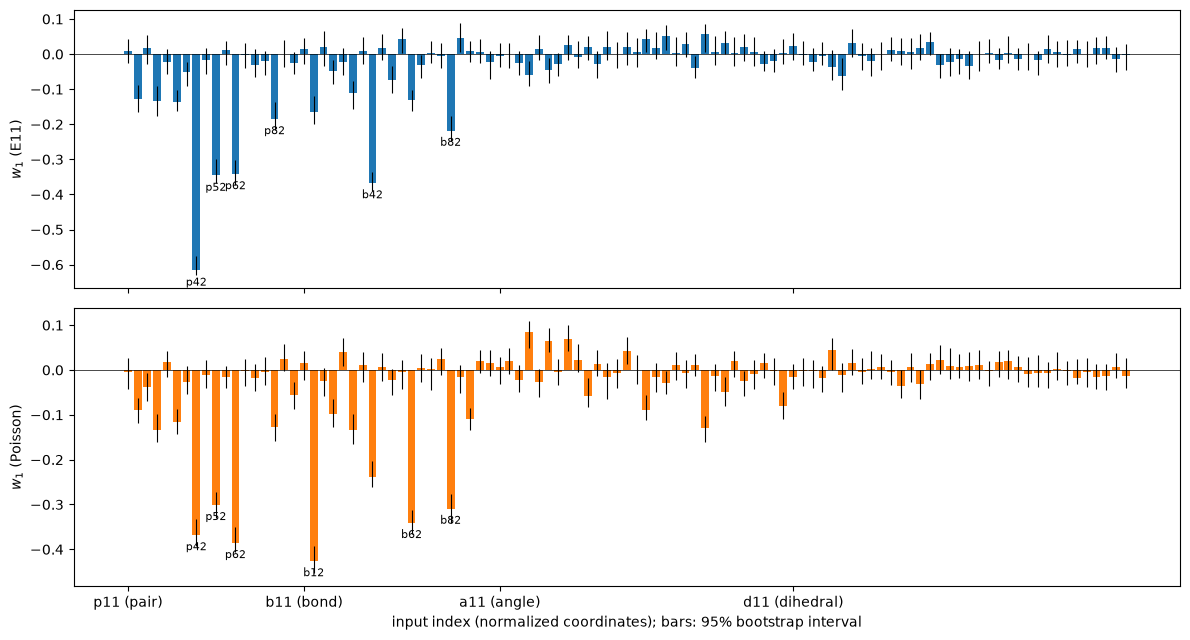

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
for ax, (label, s) in zip(axes, subs.items()):
    w = s.W1[:, 0]
    lo, hi = np.percentile(s.bootstrap_eigenvectors[:, :, 0], [2.5, 97.5], axis=0)
    ax.bar(np.arange(m), w, color='C0' if label == 'E11' else 'C1')
    ax.vlines(np.arange(m), lo, hi, color='k', lw=0.8)
    ax.axhline(0, color='k', lw=0.5)
    for i in np.argsort(-np.abs(w))[:6]:
        ax.annotate(names[i], (i, w[i]), textcoords='offset points', xytext=(0, 4 if w[i] > 0 else -11),
                    ha='center', fontsize=8)
    ax.set_ylabel(f'$w_1$ ({label})')
ticks = [0, 18, 38, 68]
axes[1].set_xticks(ticks, ['p11 (pair)', 'b11 (bond)', 'a11 (angle)', 'd11 (dihedral)'])
axes[1].set_xlabel('input index (normalized coordinates); bars: 95% bootstrap interval')
fig.tight_layout()
plt.close(fig)
fig

The active direction is dominated by a few non-bonded and bond coefficients (labelled: the six largest
components of each vector); the angle and dihedral coefficients contribute little, as the paper states
(p. 6). Signs follow the rule that the QoI decreases along $y_1$, as in the published Fig. 3. Bars are 95 %
bootstrap intervals of the sign-aligned replicates.

In [13]:
# global derivative-based indices nu_i = diag(C) (Eq. 6 of the paper), normalized by the largest
paper_top10 = {  # read from the DAS bars of Fig. 5a, b (p. 8), in order
    'E11': ['p42', 'p62', 'b42', 'p52', 'b82', 'p82', 'b12', 'p22', 'b62', 'p32'],
    'Poisson': ['b12', 'p42', 'p62', 'b62', 'b82', 'p52', 'b42', 'a112', 'p82', 'b32'],
}
top = {}
for label, s in subs.items():
    nu_i = (s.eigenvectors ** 2) @ s.eigenvalues
    order = np.argsort(-nu_i)
    top[label] = [names[i] for i in order[:10]]
    print(f'{label:8s} top 10 here: ' + ', '.join(f'{names[i]} ({nu_i[i] / nu_i[order[0]]:.2f})' for i in order[:10]))
    print(f'{"":8s} overlap with the DAS top 10 of Fig. 5: {len(set(top[label]) & set(paper_top10[label]))} of 10')
print('E and Poisson top-10 lists here share', len(set(top['E11']) & set(top['Poisson'])), 'names;',
      'in Fig. 5 they share', len(set(paper_top10['E11']) & set(paper_top10['Poisson'])))

E11      top 10 here: p42 (1.00), b42 (0.36), p52 (0.32), p62 (0.31), b82 (0.13), p82 (0.09), b12 (0.08), p32 (0.05), p22 (0.05), b62 (0.05)
         overlap with the DAS top 10 of Fig. 5: 10 of 10
Poisson  top 10 here: b12 (1.00), p62 (0.82), p42 (0.75), b62 (0.64), b82 (0.53), p52 (0.50), b42 (0.32), p22 (0.10), b32 (0.10), a112 (0.10)
         overlap with the DAS top 10 of Fig. 5: 9 of 10
E and Poisson top-10 lists here share 8 names; in Fig. 5 they share 8


The ten largest indices $\nu_i$ for $E_{11}$ are the ten names of the paper's DAS ranking in Fig. 5a (10 of
10, in a slightly different order: here p42, b42, p52, p62, then b82, p82, b12); for the Poisson ratio 9 of
the paper's 10 are here (p22 replaces p82). The two QoIs share 8 of their top-10 inputs, as the paper states
(p. 6: "8 out of the E top 10 also appear in the top 10 of the Poisson ratio"). The leading inputs p42, p62
and b42 are the LJ diameter of a hydrogen class, the LJ diameter of a carbon class and the C–H bond length,
by the defaults (2.5 Å, 3.55 Å, 1.09 Å); b12 leads for the Poisson ratio. The paper (p. 6) says that b12
and b42 "refer to the equilibrium distance of C-H and C-C atom types"; by the defaults, b12 (1.529 Å) is a
C–C and b42 (1.09 Å) a C–H bond length.

## Sufficient summary plots

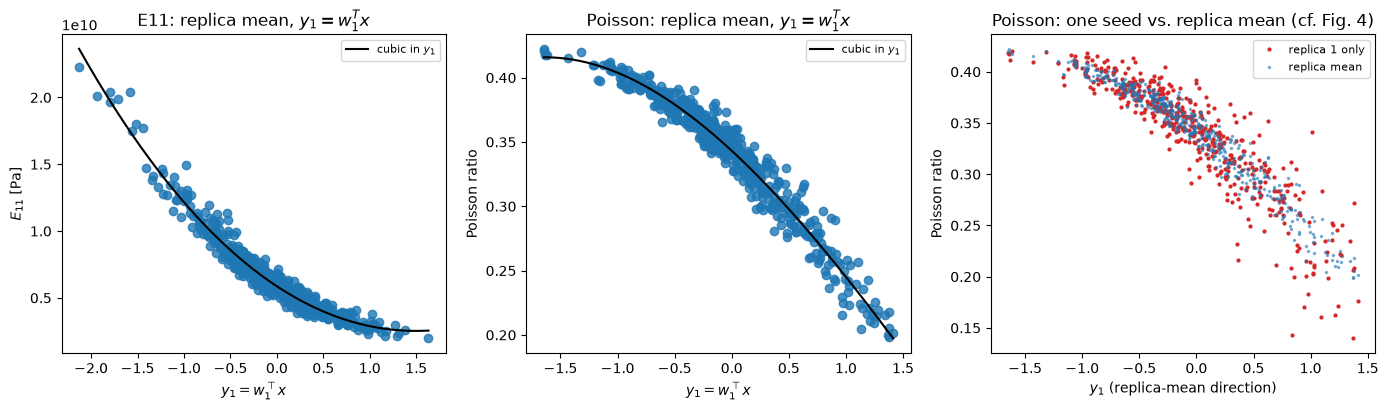

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
Z = space.to_normalized(X)
labels = {'E11': '$E_{11}$ [Pa]', 'Poisson': 'Poisson ratio'}
for ax, (label, f) in zip(axes[:2], [('E11', E), ('Poisson', nu)]):
    s = subs[label]
    ac.plotting.plot_sufficient_summary(s, X=X, f=f, qoi_label=labels[label], ax=ax)
    sg = ac.fit_surrogate(X=X, f=f, subspace=s, kind='poly', degree=3)
    yy = np.linspace((Z @ s.W1).min(), (Z @ s.W1).max(), 200)[:, None]
    ax.plot(yy, sg.evaluate(yy), 'k-', lw=1.5, label='cubic in $y_1$')
    ax.set_title(f'{label}: replica mean, $y_1 = w_1^T x$')
    ax.legend(loc='best', fontsize=8)
s = subs['Poisson']
ax = axes[2]
ax.plot(Z @ s.W1[:, 0], nu_rep[:, 0], '.', ms=4, color='C3', label='replica 1 only')
ax.plot(Z @ s.W1[:, 0], nu, '.', ms=3, color='C0', alpha=0.5, label='replica mean')
ax.set_xlabel('$y_1$ (replica-mean direction)')
ax.set_ylabel('Poisson ratio')
ax.set_title('Poisson: one seed vs. replica mean (cf. Fig. 4)')
ax.legend(fontsize=8)
fig.tight_layout()
plt.close(fig)
fig

Both replica-mean QoIs fall smoothly along $y_1$ with a narrow band about the cubic, as in the paper's
Fig. 3a, b; $E_{11}$ is convex and the Poisson ratio concave, as there. The right panel plots one replica's
Poisson ratio along the same direction: the scatter about the trend is visibly wider than for the replica
mean, the effect of the paper's Fig. 4.

In [15]:
print('one random seed (replica 1) instead of the replica mean')
for label, Y, f in [('E11', E_rep, E), ('Poisson', nu_rep, nu)]:
    s1 = ac.active_subspace(space=space, X=X, f=Y[:, 0], estimator=OPG(p=P), n=1)
    lam1 = s1.eigenvalues
    cos = abs(float(s1.W1[:, 0] @ subs[label].W1[:, 0]))
    r_one = ac.fit_surrogate(X=X, f=Y[:, 0], subspace=s1, kind='poly', degree=3).loo_r_squared
    resid_mean = np.std(ac.fit_surrogate(X=X, f=f, subspace=subs[label], kind='poly', degree=3).residuals, ddof=1)
    resid_one = np.std(ac.fit_surrogate(X=X, f=Y[:, 0], subspace=s1, kind='poly', degree=3).residuals, ddof=1)
    print(f'  {label:8s} lambda_2/lambda_1 {lam1[1] / lam1[0]:.4f}; |cos(w1 one seed, w1 mean)| {cos:.4f}; '
          f'1-D cubic LOO R^2 {r_one:.4f} (mean: {loo[label]["1-D degree 3"]:.4f}); '
          f'residual sd one seed {resid_one:.3g}, mean {resid_mean:.3g}')

one random seed (replica 1) instead of the replica mean


  E11      lambda_2/lambda_1 0.0112; |cos(w1 one seed, w1 mean)| 0.9968; 1-D cubic LOO R^2 0.9473 (mean: 0.9615); residual sd one seed 7.32e+08, mean 6.18e+08


  Poisson  lambda_2/lambda_1 0.0117; |cos(w1 one seed, w1 mean)| 0.9719; 1-D cubic LOO R^2 0.8733 (mean: 0.9606); residual sd one seed 0.0194, mean 0.0098


With one replica instead of the mean, the direction barely changes (|cos| 0.9968 for $E_{11}$, 0.9719 for the
Poisson ratio), but the scatter about the one-dimensional trend grows: the residual standard deviation of the
Poisson ratio doubles (0.0194 against 0.0098) and its LOO $R^2$ drops from 0.9606 to 0.8733; for $E_{11}$ the
drop is smaller (0.9615 to 0.9473). This quantifies the paper's statement that averaging over replicas
"visibly" reduces $\mathrm{Var}[f \mid y_1]$ for the Poisson ratio (p. 4, Fig. 4).

In [16]:
print('OLS direction (global linear fit) against the OPG direction')
for label, f in [('E11', E), ('Poisson', nu)]:
    so = ac.active_subspace(space=space, X=X, f=f, estimator='ols', n=1)
    print(f'  {label:8s} |cos(w_OLS, w_OPG)| = {abs(float(so.W1[:, 0] @ subs[label].W1[:, 0])):.4f}')
print(f'notebook run time {time.time() - T0:.0f} s')

OLS direction (global linear fit) against the OPG direction
  E11      |cos(w_OLS, w_OPG)| = 0.9937
  Poisson  |cos(w_OLS, w_OPG)| = 0.9965
notebook run time 1104 s


The global linear (OLS) direction agrees with the OPG direction (|cos| 0.9937 and 0.9965). OLS recovers the
active direction exactly only under conditions on the input law that uniform inputs do not satisfy, which is
why it serves here only as a check.

## Comparison with the paper

| quantity | paper (page) | this notebook |
|---|---|---|
| moments of $E$ (all 10,000 samples) | 6.54e9, 3.22e9, 1.61, 3.76 (Table 2, p. 6) | 6.541e+09, 3.222e+09, 1.605, 3.756 |
| moments of the Poisson ratio | 0.34, 0.053, −1.01, 0.97 (Table 2) | 0.34, 0.05274, −1.012, 0.970 |
| identity of "$E$" | Young's modulus (pp. 3–6) | stiffness component $C_{11}$; isotropic Young's modulus a median 0.605 of it |
| epistemic vs. aleatoric | epistemic dominates (p. 4, Fig. 1) | replica-noise share of the mean 8.67e-04 ($E_{11}$), 6.76e-03 (Poisson) |
| $\lambda_2/\lambda_1$, $E$ | DAS ≈ 0.03 with 95 % interval ≈ 0.01 to 0.08, read from Fig. 2a (p. 6); KAS-GP 0.0865 (authors' file `GP_eigvals`, triangle of Fig. 2a) | OPG 0.0233 to 0.0014 for $p$ = 130 to 400; 0.0101 at the default $p$ = 175 (bootstrap 0.0079 to 0.0156) |
| $\lambda_3/\lambda_1$, $\lambda_4/\lambda_1$, $E$ | DAS ≈ 0.01 and ≈ 0.004 (Fig. 2a); KAS-GP 0.0107 and 0.0061 | $\lambda_3/\lambda_1$ 0.0207 at $p$ = 130; 0.0092 and 0.0064 at $p$ = 175 |
| eigengap | "$\lambda_1 - \lambda_2$ of one order of magnitude" (DAS, p. 4) | $\lambda_1/\lambda_2$ = 42.9 to 739.1 ($E_{11}$) and 81.5 to 2144.8 (Poisson) for $p$ = 130 to 400; flat tail after it ($\lambda_2/\lambda_3$ 1.04 to 1.27) |
| Poisson eigenvalues | not reported | $\lambda_2/\lambda_1$ = 0.0046 |
| dimension | $d = 1$ (p. 4) | $n = 1$ (no second direction above the nulls) |
| 1-D fit along $y_1$ | small scatter, test data on the curve (Fig. 3a, b; p. 4) | LOO $R^2$ of a cubic 0.9615 ($E_{11}$), 0.9606 (Poisson) |
| top-10 inputs | Fig. 5a, b (p. 8) | 10 of 10 ($E$), 9 of 10 (Poisson) |
| shared top-10 inputs of $E$ and Poisson | 8 (p. 6) | 8 |
| one seed vs. replica mean, Poisson | conditional variance visibly larger (Fig. 4) | residual sd 0.0194 vs. 0.0098; LOO $R^2$ 0.8733 vs. 0.9606 |

The comparison of eigenvalue ratios depends on $p$. At the smallest $p$ (130), OPG's $\lambda_2/\lambda_1$ =
0.0233 lies inside the DAS 95 % interval of Fig. 2a (about 0.01 to 0.08 around about 0.03, read from the plot),
and its $\lambda_3/\lambda_1$ = 0.0207 is above DAS's ≈ 0.01. At the default $p$ (175) and above, OPG's
$\lambda_2/\lambda_1$ is smaller than DAS's (0.0101 against about 0.03 at $p$ = 175), while $\lambda_3/\lambda_1$
and $\lambda_4/\lambda_1$ at $p$ = 175 (0.0092 and 0.0064) are of similar size to DAS's (≈ 0.01 and ≈ 0.004). The KAS-GP ratio $\lambda_2/\lambda_1$ = 0.0865 is larger than
OPG's at every $p$ tried. The $p$ sweep and the
exact-ridge null show that each method's trailing eigenvalues reflect its own smoothing (the neighbourhood
here, the network or kernel in the paper), so the three methods agree on a one-dimensional subspace and on
its leading inputs, but their eigenvalue ratios are not comparable as measurements of the model.

## References

- W. Edeling, M. Vassaux, Y. Yang, S. Wan, S. Guillas, P. V. Coveney. Global ranking of the sensitivity of
  interaction potential contributions within classical molecular dynamics force fields. *npj Computational
  Materials* 10:87, 2024. [doi:10.1038/s41524-024-01272-z](https://doi.org/10.1038/s41524-024-01272-z)
- W. Edeling. wedeling/md-active-subspace: final release (tag 1.1). Zenodo, 2024.
  [doi:10.5281/zenodo.10817481](https://doi.org/10.5281/zenodo.10817481); https://github.com/wedeling/MD-active-subspace
- P. G. Constantine. *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*. SIAM,
  2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860)
- P. G. Constantine, E. Dow, Q. Wang. Active subspace methods in theory and practice: applications to
  kriging surfaces. *SIAM Journal on Scientific Computing* 36(4):A1500–A1524, 2014.
  [doi:10.1137/130916138](https://doi.org/10.1137/130916138)
- Y. Xia, H. Tong, W. K. Li, L.-X. Zhu. An adaptive estimation of dimension reduction space. *Journal of the
  Royal Statistical Society B* 64(3):363–410, 2002. [doi:10.1111/1467-9868.03411](https://doi.org/10.1111/1467-9868.03411)
- W. Edeling. On the deep active-subspace method. *SIAM/ASA Journal on Uncertainty Quantification*
  11:62–90, 2023. [doi:10.1137/21M1463240](https://doi.org/10.1137/21M1463240)
- A. P. Thompson et al. LAMMPS – a flexible simulation tool for particle-based materials modeling at the
  atomic, meso, and continuum scales. *Computer Physics Communications* 271:108171, 2022.
  [doi:10.1016/j.cpc.2021.108171](https://doi.org/10.1016/j.cpc.2021.108171)

## Acknowledgments

The paper acknowledges funding from the UK EPSRC (UK High-End Computing Consortium EP/R029598/1; SEAVEA
EP/W007762/1; UKCOMES EP/L00030X/1; CompBioMedX EP/X019276/1), the UK MRC Medical Bioinformatics project
(MR/L016311/1), and the European Commission (EU H2020 CompBioMed2 Centre of Excellence 823712; EU H2020
EXDCI-2 800957), and computing time on SuperMUC-NG (Leibniz Supercomputing Centre, project COVID-19-SNG1) and
ARCHER2 (under SEAVEA EP/W007762/1).